# Generate Geographical Hierarchical Data from Simulated MMM Dataset

This notebook transforms the simulated MMM data (`df_mmm_simu.csv`) into a geographical hierarchical format suitable for multi-dimensional MMM analysis.

**Input:** `data/df_mmm_simu.csv` - Single region/market data

**Output:** `data/df_mmm_simu_geo.csv` - Multi-region data with `geo` dimension

**Strategy:** 
- Create multiple geographical regions (e.g., geo_a, geo_b, geo_c)
- Each region gets the base data with variations to simulate different market characteristics:
  - Different spend levels (some regions have higher/lower budgets)
  - Different response patterns (channel effectiveness varies by geo)
  - Different baseline levels (market size differences)
  - Shared seasonality patterns (all regions have similar seasonal trends)

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(327)

## 1. Load Original Simulated Data

In [2]:
# Load original data
df_original = pd.read_csv('data/df_mmm_simu.csv')

print(f"Original data shape: {df_original.shape}")
print(f"\nDate range: {df_original['week_start_date'].min()} to {df_original['week_start_date'].max()}")
print(f"Number of weeks: {len(df_original)}")
print(f"\nColumns: {list(df_original.columns)}")
df_original.head()

Original data shape: (140, 17)

Date range: 2023-01-28 to 2025-09-27
Number of weeks: 140

Columns: ['week_start_date', 'Intercept', 'Trend', 'Fourier_sin_1', 'Fourier_cos_1', 'Fourier_sin_2', 'Fourier_cos_2', 'Holiday_Christmas', 'Control_1', 'Control_2', 'MV_Unpaid_1_visits', 'MV_Unpaid_2_visits', 'MV_Paid_1_Spend', 'MV_Paid_1_visits', 'MV_Paid_2_Spend', 'MV_Paid_2_visits', 'KPI']


,week_start_date,Intercept,Trend,Fourier_sin_1,Fourier_cos_1,Fourier_sin_2,Fourier_cos_2,Holiday_Christmas,Control_1,Control_2,MV_Unpaid_1_visits,MV_Unpaid_2_visits,MV_Paid_1_Spend,MV_Paid_1_visits,MV_Paid_2_Spend,MV_Paid_2_visits,KPI
0,2023-01-28,1,1,0.000000,1.000000,0.000000,1.000000,0,0.496714,116.381149,100.000000,100.000000,917.624607,18165.940444,500.000000,3843.416917,105062.901830
1,2023-02-04,1,2,0.120537,0.992709,0.239316,0.970942,0,0.138264,112.424026,100.000000,100.000000,931.255734,18494.753023,500.000000,4008.569354,100154.130052
2,2023-02-11,1,3,0.239316,0.970942,0.464723,0.885456,0,0.647689,110.592654,100.000000,100.000000,971.042319,17738.157316,507.026442,2928.068871,108741.462944
3,2023-02-18,1,4,0.354605,0.935016,0.663123,0.748511,0,1.523030,106.106006,145.219227,133.585944,1165.221364,18982.038773,551.433524,4546.707517,118425.126125
4,2023-02-25,1,5,0.464723,0.885456,0.822984,0.568065,0,0.234153,104.627937,299.298986,131.501936,1030.911018,18319.456422,507.458134,2505.155811,102655.089414


## 2. Define Geographical Variations

We'll create 3 geographical regions with different characteristics:

In [3]:
# Define geographical regions and their characteristics
geo_config = {
    'geo_north': {
        'spend_multiplier': 1.0,      # Base spending level
        'baseline_multiplier': 1.0,   # Base market size
        'channel_effectiveness': {    # Channel response variations
            'MV_Unpaid_1_visits': 1.2,  # 20% more effective
            'MV_Unpaid_2_visits': 0.9,  # 10% less effective
            'MV_Paid_1_visits': 1.0,    # Same effectiveness
            'MV_Paid_2_visits': 1.1,    # 10% more effective
        },
        'noise_level': 0.05  # 5% noise in KPI
    },
    'geo_south': {
        'spend_multiplier': 1.3,      # 30% higher budget
        'baseline_multiplier': 1.4,   # 40% larger market
        'channel_effectiveness': {
            'MV_Unpaid_1_visits': 0.8,  # 20% less effective
            'MV_Unpaid_2_visits': 1.3,  # 30% more effective
            'MV_Paid_1_visits': 1.2,    # 20% more effective
            'MV_Paid_2_visits': 0.9,    # 10% less effective
        },
        'noise_level': 0.08  # 8% noise (more volatile market)
    },
    'geo_central': {
        'spend_multiplier': 0.7,      # 30% lower budget (smaller region)
        'baseline_multiplier': 0.6,   # 40% smaller market
        'channel_effectiveness': {
            'MV_Unpaid_1_visits': 1.0,
            'MV_Unpaid_2_visits': 1.1,
            'MV_Paid_1_visits': 0.85,   # 15% less effective
            'MV_Paid_2_visits': 1.0,
        },
        'noise_level': 0.06  # 6% noise
    }
}

print("Geographical regions configuration:")
for geo, config in geo_config.items():
    print(f"\n{geo.upper()}:")
    print(f"  - Spend level: {config['spend_multiplier']:.1%} of base")
    print(f"  - Market size: {config['baseline_multiplier']:.1%} of base")
    print(f"  - Noise level: {config['noise_level']:.1%}")

Geographical regions configuration:

GEO_NORTH:
  - Spend level: 100.0% of base
  - Market size: 100.0% of base
  - Noise level: 5.0%

GEO_SOUTH:
  - Spend level: 130.0% of base
  - Market size: 140.0% of base
  - Noise level: 8.0%

GEO_CENTRAL:
  - Spend level: 70.0% of base
  - Market size: 60.0% of base
  - Noise level: 6.0%


## 3. Generate Multi-Geo Dataset

Transform the original data by:
1. Replicating data for each geo
2. Applying spend multipliers to channel/spend columns
3. Applying effectiveness multipliers to visits columns
4. Adjusting KPI based on baseline and channel effectiveness
5. Adding realistic noise

In [4]:
# Identify column types
date_col = 'week_start_date'
target_col = 'KPI'

# Channel columns (visits and spend)
channel_visit_cols = ['MV_Unpaid_1_visits', 'MV_Unpaid_2_visits', 'MV_Paid_1_visits', 'MV_Paid_2_visits']
channel_spend_cols = ['MV_Paid_1_Spend', 'MV_Paid_2_Spend']

# Control/feature columns (keep same across geos)
control_cols = ['Intercept', 'Trend', 'Fourier_sin_1', 'Fourier_cos_1', 'Fourier_sin_2', 
                'Fourier_cos_2', 'Holiday_Christmas', 'Control_1', 'Control_2']

# Also need unpaid columns (they act as both spend and visits)
unpaid_cols = ['MV_Unpaid_1_visits', 'MV_Unpaid_2_visits']

print(f"Channel visit columns: {channel_visit_cols}")
print(f"Channel spend columns: {channel_spend_cols}")
print(f"Control columns: {control_cols}")
print(f"Unpaid columns (both spend & visits): {unpaid_cols}")

Channel visit columns: ['MV_Unpaid_1_visits', 'MV_Unpaid_2_visits', 'MV_Paid_1_visits', 'MV_Paid_2_visits']
Channel spend columns: ['MV_Paid_1_Spend', 'MV_Paid_2_Spend']
Control columns: ['Intercept', 'Trend', 'Fourier_sin_1', 'Fourier_cos_1', 'Fourier_sin_2', 'Fourier_cos_2', 'Holiday_Christmas', 'Control_1', 'Control_2']
Unpaid columns (both spend & visits): ['MV_Unpaid_1_visits', 'MV_Unpaid_2_visits']


In [5]:
def generate_geo_data(df_base, geo_name, geo_config):
    """
    Generate geographical variant of the base dataset.
    
    Parameters:
    -----------
    df_base : pd.DataFrame
        Original simulated data
    geo_name : str
        Name of the geographical region
    geo_config : dict
        Configuration dictionary with multipliers and effectiveness
    
    Returns:
    --------
    pd.DataFrame
        Transformed data for the specific geo
    """
    df_geo = df_base.copy()
    
    # Add geo column
    df_geo.insert(1, 'geo', geo_name)
    
    # Get multipliers
    spend_mult = geo_config['spend_multiplier']
    baseline_mult = geo_config['baseline_multiplier']
    effectiveness = geo_config['channel_effectiveness']
    noise_level = geo_config['noise_level']
    
    # 1. Apply spend multipliers to spend columns
    for col in channel_spend_cols:
        df_geo[col] = df_geo[col] * spend_mult
    
    # 2. Apply spend multipliers to unpaid columns (they represent impressions/traffic)
    for col in unpaid_cols:
        df_geo[col] = df_geo[col] * spend_mult
    
    # 3. Adjust visits based on effectiveness
    # This simulates different conversion rates / channel performance by geo
    for col in channel_visit_cols:
        if col in effectiveness:
            # Apply effectiveness modifier
            df_geo[col] = df_geo[col] * effectiveness[col]
    
    # 4. Recalculate KPI based on new channel contributions
    # Strategy: Scale original KPI by baseline, then adjust based on channel changes
    
    # Start with baseline adjustment
    df_geo[target_col] = df_geo[target_col] * baseline_mult
    
    # Calculate average effectiveness change across all channels
    avg_effectiveness = np.mean(list(effectiveness.values()))
    
    # Adjust KPI by average channel effectiveness change
    # (This simulates that better channels = more revenue)
    df_geo[target_col] = df_geo[target_col] * avg_effectiveness
    
    # 5. Add realistic noise to KPI
    n_rows = len(df_geo)
    noise = np.random.normal(1.0, noise_level, n_rows)
    df_geo[target_col] = df_geo[target_col] * noise
    
    # Ensure no negative values
    df_geo[target_col] = df_geo[target_col].clip(lower=0)
    
    return df_geo

print("Function defined: generate_geo_data()")

Function defined: generate_geo_data()


In [6]:
# Generate data for all geos
geo_dfs = []

for geo_name, config in geo_config.items():
    print(f"Generating data for {geo_name}...")
    df_geo = generate_geo_data(df_original, geo_name, config)
    geo_dfs.append(df_geo)
    print(f"  - Generated {len(df_geo)} rows")
    print(f"  - KPI range: {df_geo['KPI'].min():.2f} to {df_geo['KPI'].max():.2f}")
    print(f"  - KPI mean: {df_geo['KPI'].mean():.2f}")

# Combine all geos
df_geo_combined = pd.concat(geo_dfs, ignore_index=True)

print(f"\n{'='*60}")
print(f"COMBINED DATASET")
print(f"{'='*60}")
print(f"Total rows: {len(df_geo_combined)}")
print(f"Number of geos: {df_geo_combined['geo'].nunique()}")
print(f"Rows per geo: {len(df_geo_combined) // df_geo_combined['geo'].nunique()}")
print(f"\nGeo distribution:")
print(df_geo_combined['geo'].value_counts())

Generating data for geo_north...
  - Generated 140 rows
  - KPI range: 88092.43 to 180856.47
  - KPI mean: 121287.29
Generating data for geo_south...
  - Generated 140 rows
  - KPI range: 113055.55 to 283411.81
  - KPI mean: 169167.47
Generating data for geo_central...
  - Generated 140 rows
  - KPI range: 45192.85 to 97197.54
  - KPI mean: 68535.61

COMBINED DATASET
Total rows: 420
Number of geos: 3
Rows per geo: 140

Geo distribution:
geo
geo_north      140
geo_south      140
geo_central    140
Name: count, dtype: int64


## 4. Verify Data Structure

In [7]:
# Display first few rows
print("First 10 rows (showing key columns):")
key_cols = ['week_start_date', 'geo', 'MV_Paid_1_Spend', 'MV_Paid_1_visits', 'MV_Paid_2_Spend', 'MV_Paid_2_visits', 'KPI']
df_geo_combined[key_cols].head(10)

First 10 rows (showing key columns):


,week_start_date,geo,MV_Paid_1_Spend,MV_Paid_1_visits,MV_Paid_2_Spend,MV_Paid_2_visits,KPI
0,2023-01-28,geo_north,917.624607,18165.940444,500.000000,4227.758609,119779.077224
1,2023-02-04,geo_north,931.255734,18494.753023,500.000000,4409.426289,103068.728992
2,2023-02-11,geo_north,971.042319,17738.157316,507.026442,3220.875758,112479.271244
3,2023-02-18,geo_north,1165.221364,18982.038773,551.433524,5001.378269,113205.893493
4,2023-02-25,geo_north,1030.911018,18319.456422,507.458134,2755.671392,113054.028187
5,2023-03-04,geo_north,1201.839863,18288.141085,545.037071,3931.286032,113600.317837
6,2023-03-11,geo_north,1587.742030,19384.652547,526.597911,5780.136179,123721.001857
7,2023-03-18,geo_north,1375.663790,18337.256351,526.142041,5797.181020,110970.110828
8,2023-03-25,geo_north,1165.011121,17815.625373,543.863595,5685.894630,103812.604487
9,2023-04-01,geo_north,1499.235590,18010.587018,502.251264,3977.274500,118418.219348


In [8]:
# Summary statistics by geo
print("\nKPI Statistics by Geo:")
print(df_geo_combined.groupby('geo')['KPI'].describe())

print("\n" + "="*60)
print("Spend Statistics by Geo (MV_Paid_1_Spend):")
print(df_geo_combined.groupby('geo')['MV_Paid_1_Spend'].describe())


KPI Statistics by Geo:
             count           mean           std            min            25%  \
geo                                                                             
geo_central  140.0   68535.613730  10757.081192   45192.852657   61348.813219   
geo_north    140.0  121287.291503  18548.325312   88092.428293  109074.023450   
geo_south    140.0  169167.473228  28159.274893  113055.553763  149770.795645   

                       50%            75%            max  
geo                                                       
geo_central   67405.279481   75585.685161   97197.536491  
geo_north    118048.108996  134763.195866  180856.467750  
geo_south    166923.688931  182602.283850  283411.809192  

Spend Statistics by Geo (MV_Paid_1_Spend):
             count         mean          std          min          25%  \
geo                                                                      
geo_central  140.0  2102.613974   826.102661   636.245299  1413.545495   
geo_north

In [9]:
# Check for missing values
print("\nMissing values check:")
missing = df_geo_combined.isnull().sum()
if missing.sum() == 0:
    print("✓ No missing values")
else:
    print(missing[missing > 0])

# Check data types
print("\nData types:")
print(df_geo_combined.dtypes)


Missing values check:
✓ No missing values

Data types:
week_start_date        object
geo                    object
Intercept               int64
Trend                   int64
Fourier_sin_1         float64
Fourier_cos_1         float64
Fourier_sin_2         float64
Fourier_cos_2         float64
Holiday_Christmas       int64
Control_1             float64
Control_2             float64
MV_Unpaid_1_visits    float64
MV_Unpaid_2_visits    float64
MV_Paid_1_Spend       float64
MV_Paid_1_visits      float64
MV_Paid_2_Spend       float64
MV_Paid_2_visits      float64
KPI                   float64
dtype: object


## 5. Visualize Geographical Differences

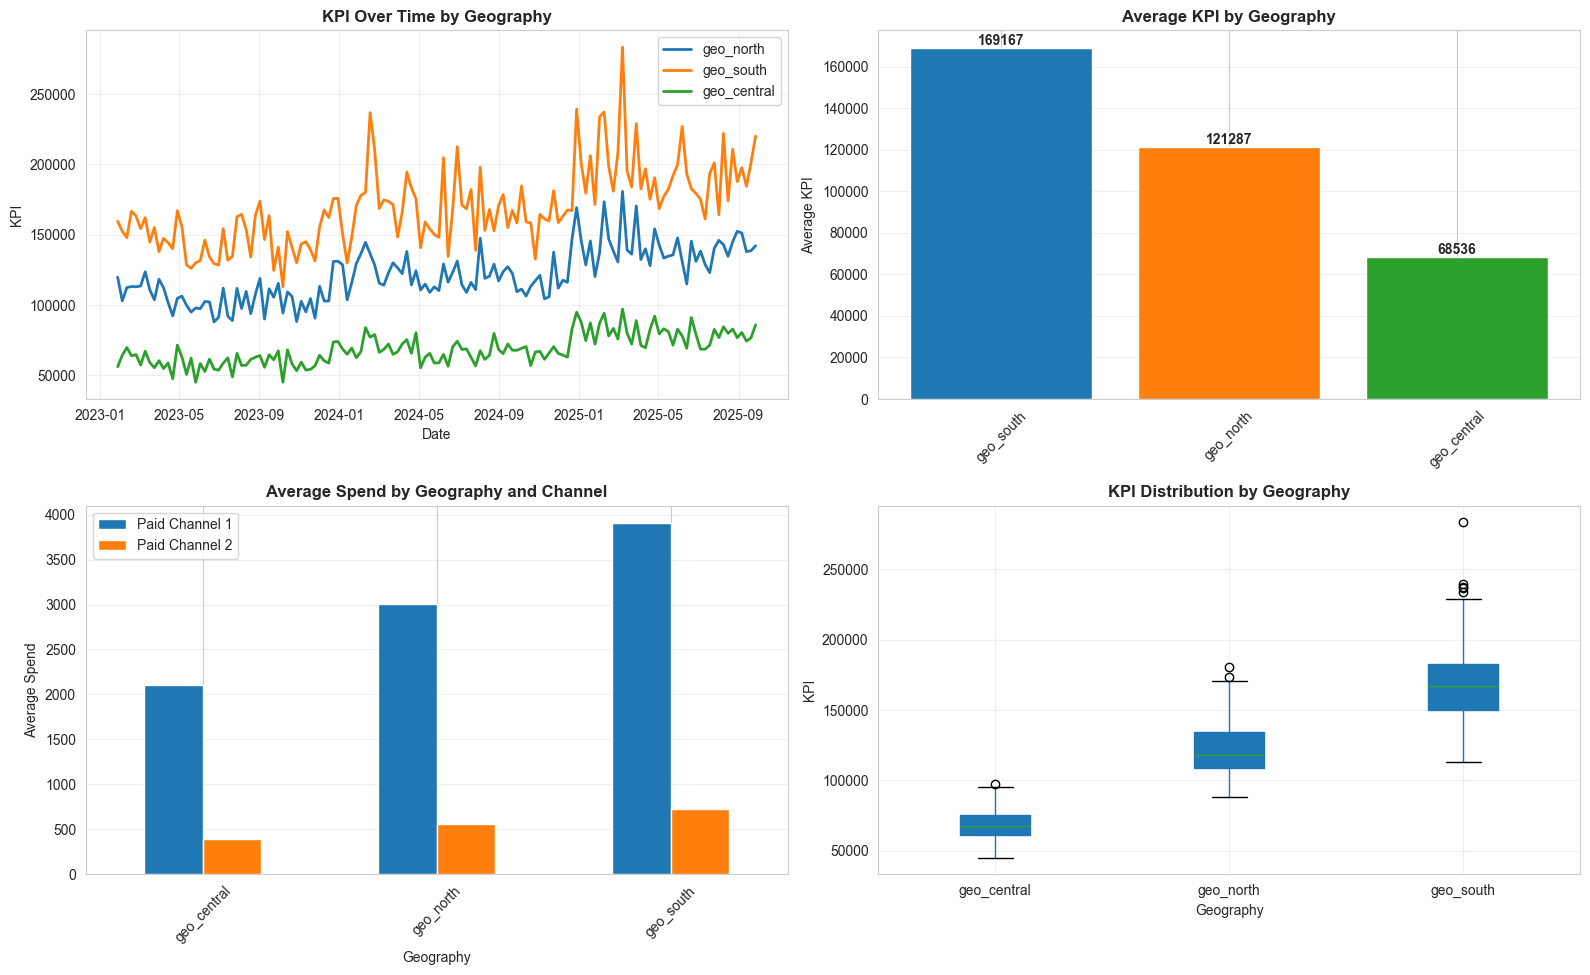


✓ Visualization complete!


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)

# Create figure
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Geographical Variations in MMM Data', fontsize=16, fontweight='bold')

# 1. KPI time series by geo
ax1 = axes[0, 0]
for geo in df_geo_combined['geo'].unique():
    geo_data = df_geo_combined[df_geo_combined['geo'] == geo]
    ax1.plot(pd.to_datetime(geo_data['week_start_date']), geo_data['KPI'], label=geo, linewidth=2)
ax1.set_title('KPI Over Time by Geography', fontsize=12, fontweight='bold')
ax1.set_xlabel('Date')
ax1.set_ylabel('KPI')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Average KPI by geo (bar chart)
ax2 = axes[0, 1]
kpi_by_geo = df_geo_combined.groupby('geo')['KPI'].mean().sort_values(ascending=False)
bars = ax2.bar(range(len(kpi_by_geo)), kpi_by_geo.values, color=['#1f77b4', '#ff7f0e', '#2ca02c'])
ax2.set_xticks(range(len(kpi_by_geo)))
ax2.set_xticklabels(kpi_by_geo.index, rotation=45)
ax2.set_title('Average KPI by Geography', fontsize=12, fontweight='bold')
ax2.set_ylabel('Average KPI')
ax2.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.0f}',
             ha='center', va='bottom', fontweight='bold')

# 3. Spend comparison by geo
ax3 = axes[1, 0]
spend_by_geo = df_geo_combined.groupby('geo')[['MV_Paid_1_Spend', 'MV_Paid_2_Spend']].mean()
spend_by_geo.plot(kind='bar', ax=ax3, color=['#1f77b4', '#ff7f0e'])
ax3.set_title('Average Spend by Geography and Channel', fontsize=12, fontweight='bold')
ax3.set_xlabel('Geography')
ax3.set_ylabel('Average Spend')
ax3.legend(['Paid Channel 1', 'Paid Channel 2'])
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=45)
ax3.grid(True, alpha=0.3, axis='y')

# 4. Box plot of KPI distribution by geo
ax4 = axes[1, 1]
df_geo_combined.boxplot(column='KPI', by='geo', ax=ax4, patch_artist=True)
ax4.set_title('KPI Distribution by Geography', fontsize=12, fontweight='bold')
ax4.set_xlabel('Geography')
ax4.set_ylabel('KPI')
plt.suptitle('')  # Remove the automatic title from boxplot
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✓ Visualization complete!")

## 6. Save Multi-Geo Dataset

In [11]:
# Sort by date and geo for consistency
df_geo_combined = df_geo_combined.sort_values(['week_start_date', 'geo']).reset_index(drop=True)

# Save to CSV
output_path = 'data/df_mmm_simu_geo.csv'
df_geo_combined.to_csv(output_path, index=False)

print(f"✓ Multi-geo dataset saved to: {output_path}")
print(f"\nFinal dataset info:")
print(f"  - Shape: {df_geo_combined.shape}")
print(f"  - Geographies: {list(df_geo_combined['geo'].unique())}")
print(f"  - Date range: {df_geo_combined['week_start_date'].min()} to {df_geo_combined['week_start_date'].max()}")
print(f"  - Columns: {len(df_geo_combined.columns)}")

✓ Multi-geo dataset saved to: data/df_mmm_simu_geo.csv

Final dataset info:
  - Shape: (420, 18)
  - Geographies: ['geo_central', 'geo_north', 'geo_south']
  - Date range: 2023-01-28 to 2025-09-27
  - Columns: 18


## 7. Generate Configuration File for Geo Model

Create a YAML config file for the hierarchical MMM model:

In [12]:
# We'll create a config file based on the original but with geo dimension
config_yaml = '''# MMM Configuration File - HIERARCHICAL GEO MODEL
# Generated from gen_geodata.ipynb

# ============================================================================
# DATA SOURCE
# ============================================================================
source: &data_source "data/df_mmm_simu_geo.csv"

# ============================================================================
# MODEL CONFIGURATION
# ============================================================================
model:
  # HIERARCHICAL DIMENSION - This enables geographical hierarchical modeling
  dims: ["geo"]  # Model will create separate parameters per geography

  # Adstock transformation parameters
  adstock:
    type: "GeometricAdstock"
    l_max: 8

  # Saturation transformation parameters
  saturation:
    type: "NoSaturation"

  # Seasonality configuration
  seasonality:
    yearly_seasonality: 2

  # Time-varying parameters
  time_varying:
    intercept: false
    media: false

  # Scaling configuration
  apply_scaling: false

  # Intercept configuration
  fit_intercept: true

  # Data validation
  validate_data: true

  # Log transformation configuration
  log_transformation:
    - "target"
    - "channels"

# ============================================================================
# DATA CONFIGURATION
# ============================================================================
data:
  source: *data_source

  columns:
    date_column: "week_start_date"
    target_column: "KPI"
    
    # Dimension column for hierarchical modeling
    dim_columns:
      - "geo"

    channels:
      - name: "MV_Unpaid_1_visits"
        spend_column: "MV_Unpaid_1_visits"
        type: "unpaid"
        adstock:
          prior:
            distribution: "Beta"
            alpha: 2
            beta: 2
        saturation:
          prior:
            distribution: "TruncatedNormal"
            mu: 0.5
            sigma: 0.3
            lower: 0.0
            upper: 2.0

      - name: "MV_Unpaid_2_visits"
        spend_column: "MV_Unpaid_2_visits"
        type: "unpaid"
        adstock:
          prior:
            distribution: "Beta"
            alpha: 1
            beta: 3
        saturation:
          prior:
            distribution: "TruncatedNormal"
            mu: 0.6
            sigma: 0.35
            lower: 0.0
            upper: 2.0

      - name: "MV_Paid_1_visits"
        spend_column: "MV_Paid_1_Spend"
        type: "paid"
        adstock:
          prior:
            distribution: "Beta"
            alpha: 1
            beta: 3
        saturation:
          prior:
            distribution: "TruncatedNormal"
            mu: 1.0
            sigma: 0.5
            lower: 0.0
            upper: 5.0

      - name: "MV_Paid_2_visits"
        spend_column: "MV_Paid_2_Spend"
        type: "paid"
        adstock:
          prior:
            distribution: "Beta"
            alpha: 1
            beta: 3
        saturation:
          prior:
            distribution: "TruncatedNormal"
            mu: 1.1
            sigma: 0.55
            lower: 0.0
            upper: 5.0

    controls:
      - name: "Control_1"
        prior:
          distribution: "Normal"
          mu: 0
          sigma: 0.05

      - name: "Control_2"
        prior:
          distribution: "Normal"
          mu: 0
          sigma: 0.03

      - name: "Holiday_Christmas"
        prior:
          distribution: "Normal"
          mu: 0
          sigma: 0.1

# ============================================================================
# PRIOR CONFIGURATION
# ============================================================================
priors:
  # Intercept prior - WILL VARY BY GEO (hierarchical)
  intercept:
    distribution: "Normal"
    mu: 0.5
    sigma: 0.2
    dims: "geo"  # Each geo gets its own intercept

  # Gamma fourier prior (for seasonality)
  gamma_fourier:
    distribution: "Laplace"
    mu: 0
    b: 0.2

  # Likelihood prior - WILL VARY BY GEO
  likelihood:
    distribution: "Normal"
    sigma:
      distribution: "HalfNormal"
      sigma: 6
      dims: "geo"  # Each geo gets its own noise level

# ============================================================================
# SAMPLING CONFIGURATION
# ============================================================================
sampling:
  random_seed: 327

  prior_predictive:
    samples: 300

  mcmc:
    chains: 2
    target_accept: 0.85
    nuts_sampler: "numpyro"

  progressbar: true

# ============================================================================
# VISUALIZATION CONFIGURATION
# ============================================================================
visualization:
  figure:
    figsize: [12, 7]
    dpi: 100

  style: "arviz-darkgrid"

  backend:
    format: "retina"

# ============================================================================
# LOGGING CONFIGURATION
# ============================================================================
logging:
  enabled: false
  level: "INFO"
  format: "%(asctime)s - %(name)s - %(levelname)s - %(message)s"
  date_format: "%Y-%m-%d %H:%M:%S"

  mmm_logger:
    name: "pymc_marketing.mmm.mmm.MMM"
    level: "INFO"

# ============================================================================
# ANALYSIS CONFIGURATION
# ============================================================================
analysis:
  contribution_grid:
    start: 0
    stop: 1.5
    num: 12
    absolute_xrange: true

  baseline_components:
    - "intercept"
    - "seasonality"
'''

# Save config file
config_output_path = 'mmm_config_simu_geo.yml'
with open(config_output_path, 'w') as f:
    f.write(config_yaml)

print(f"✓ Configuration file saved to: {config_output_path}")
print("\nKey hierarchical features:")
print("  - dims: ['geo'] - Enables geographical hierarchy")
print("  - Intercept has dims: geo - Separate baseline per region")
print("  - Likelihood sigma has dims: geo - Separate noise level per region")
print("\nYou can now use this config with the MMM class to fit a hierarchical model!")

✓ Configuration file saved to: mmm_config_simu_geo.yml

Key hierarchical features:
  - dims: ['geo'] - Enables geographical hierarchy
  - Intercept has dims: geo - Separate baseline per region
  - Likelihood sigma has dims: geo - Separate noise level per region

You can now use this config with the MMM class to fit a hierarchical model!


## Summary

This notebook successfully:

1. ✅ Loaded the original simulated MMM data (`df_mmm_simu.csv`)
2. ✅ Created 3 geographical regions with different characteristics:
   - **geo_north**: Base market (normal spend, good performance on Unpaid 1)
   - **geo_south**: Large market (30% higher spend, 40% larger, best performance on Unpaid 2)
   - **geo_central**: Small market (30% lower spend, 40% smaller, moderate performance)
3. ✅ Applied realistic variations:
   - Spend levels differ by geography
   - Channel effectiveness varies (partial pooling will help estimate these!)
   - Market sizes differ (different baseline KPI levels)
   - Added appropriate noise levels
4. ✅ Generated multi-geo dataset with proper structure
5. ✅ Created configuration file for hierarchical MMM modeling

**Next Steps:**
- Use `mmm_config_simu_geo.yml` to fit a hierarchical MMM model
- Compare channel effectiveness across geographies
- Analyze how partial pooling helps with lower-signal markets
- Generate geo-specific ROAS and contribution analysis